# Bright and dark modes from MCWF


In [1]:
%reload_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import numpy as np

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from common.plotting import plot_harmonic_sweep, plot_spin_components
from common.utils.parameters import mcwf_dt_from_scales, omega_c, scaled_N_Gamma
from common.utils.phases import default_three_phase_protocol
from parser.mcwf import MCWFSolverParameters
from parser.mfe import MFESolverParameters
from parser.moments import MomentSeries, SimulationMetadata
from post_analysis import (
    compute_windowed_harmonic_analysis,
    compute_j_modes_from_j_moments,
    compute_j_moments,
    compute_mean_generator_moments,
    extract_family_phase_series,
)
from solvers.mcwf.ensamble_sim import run_trajectory_ensemble
from solvers.mfe import compute_mfe_j_moments, solve_mfe

/Users/ashar/.pyenv/versions/cavity-OAT_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters


In [2]:
# Shared physical and saved-time parameters
Gamma = 1.0
num_snapshots = 500
Ni = [5, 5]
omega_i = [0.7]

# MCWF ensemble and initial-sector parameters
dN = 0
ntraj = 500
seed = 1234
n_processes = 8
max_omega_over_omega_c = None
linear_constraints = None
joint_probability = None

# N*Gamma-scaled model parameters and standard three-phase protocol
N_total = sum(Ni)
Omega_factor = 0.1
Omega0 = scaled_N_Gamma(Omega_factor, N_total, Gamma)
delta_factor = 0.02
delta0 = scaled_N_Gamma(delta_factor, N_total, Gamma)
dt = mcwf_dt_from_scales(Omega0, delta0, N_total, Gamma)
phase_durations = (10.0, 10000.0, 10.0)

save_plots = False
output_dir = repo_root / "output" / "bright_dark_modes_mcwf"

if len(Ni) != 2 or len(omega_i) != 1:
    raise ValueError("This notebook expects two groups and one independent coupling.")

print(f"N_total = {N_total}; Ni = {Ni}")
print(f"Omega0 = {Omega0}")
print(f"Omega/Omega_c at NJ=N/2 = {Omega0 / omega_c(N_total // 2, Gamma):.3f}")
print(f"delta0 = {delta0}; delta/(N*Gamma) = {delta_factor:.3f}")
print(f"dt = {dt}")

phase_protocol = default_three_phase_protocol(
    durations=phase_durations,
    delta0=delta0,
    Omega0=Omega0,
)
simulation_metadata = SimulationMetadata(
    Ni=tuple(Ni),
    omega_i=tuple(omega_i),
    Gamma=Gamma,
    phase_protocol=phase_protocol,
)
mcwf_moments = MomentSeries(
    num_snapshots=num_snapshots,
    metadata=simulation_metadata,
)
mcwf_parameters = MCWFSolverParameters(
    Ni=simulation_metadata.Ni,
    omega_i=simulation_metadata.omega_groups,
    Gamma=simulation_metadata.Gamma,
    phase_protocol=simulation_metadata.phase_protocol,
    dN=dN,
    max_omega_over_omega_c=max_omega_over_omega_c,
    linear_constraints=linear_constraints,
    joint_probability=joint_probability,
    sector_distribution="binomial",
    dt=dt,
    shifted_jump_operator=True,
)

# MFE uses the same physical inputs, protocol, and saved-time grid.
mfe_moments = MomentSeries(
    t=mcwf_moments.t.copy(),
    metadata=simulation_metadata,
)
mfe_parameters = MFESolverParameters(
    Ni=simulation_metadata.Ni,
    omega_i=simulation_metadata.omega_groups,
    Gamma=simulation_metadata.Gamma,
    phase_protocol=simulation_metadata.phase_protocol,
)
print(f"Group couplings = {simulation_metadata.omega_groups}")


N_total = 10; Ni = [5, 5]
Omega0 = 1.0
Omega/Omega_c at NJ=N/2 = 0.400
delta0 = 0.2; delta/(N*Gamma) = 0.020
dt = 0.01
Group couplings = (0.7, 1.3)


## MCWF and MFE simulations

In [3]:
mcwf_ensemble = run_trajectory_ensemble(
    mcwf_parameters,
    t_eval=mcwf_moments.t,
    seed=seed,
    ntraj=ntraj,
    n_processes=n_processes,
)
mcwf_moments.generator_moments = mcwf_ensemble.moments

mfe_result = solve_mfe(
    mfe_parameters,
    t_eval=mfe_moments.t,
)
if not mfe_result.success:
    raise RuntimeError(mfe_result.message)

Initial sector construction: 36 sectors.

Filter                       Sectors left   Sector % input   Sector % initial   Probability % input   Probability % initial
---------------------------------------------------------------------------------------------------------------------------
dN filter                               6           16.67%             16.67%                24.61%                  24.61%


simulate trajectories: 100%|██████████| 500/500 [22:46<00:00,  2.73s/it]


Simulation step summary (avg per trajectory): total steps=1004213.88, steps without precompute=2222.70


## Ensemble J moments and collective modes


In [4]:
mcwf_moments.mean_generator_moments = compute_mean_generator_moments(
    mcwf_moments.generator_moments,
)
mcwf_moments.J = compute_j_moments(
    mcwf_moments.mean_generator_moments,
    metadata=mcwf_moments.metadata,
)
mfe_moments.J = compute_mfe_j_moments(mfe_result)

# Use the same active-population normalization for both methods.
for moments in (mcwf_moments, mfe_moments):
    moments.J_modes = compute_j_modes_from_j_moments(
        moments.J,
        omega_groups=moments.metadata.omega_groups,
    )


## Bright and dark modes


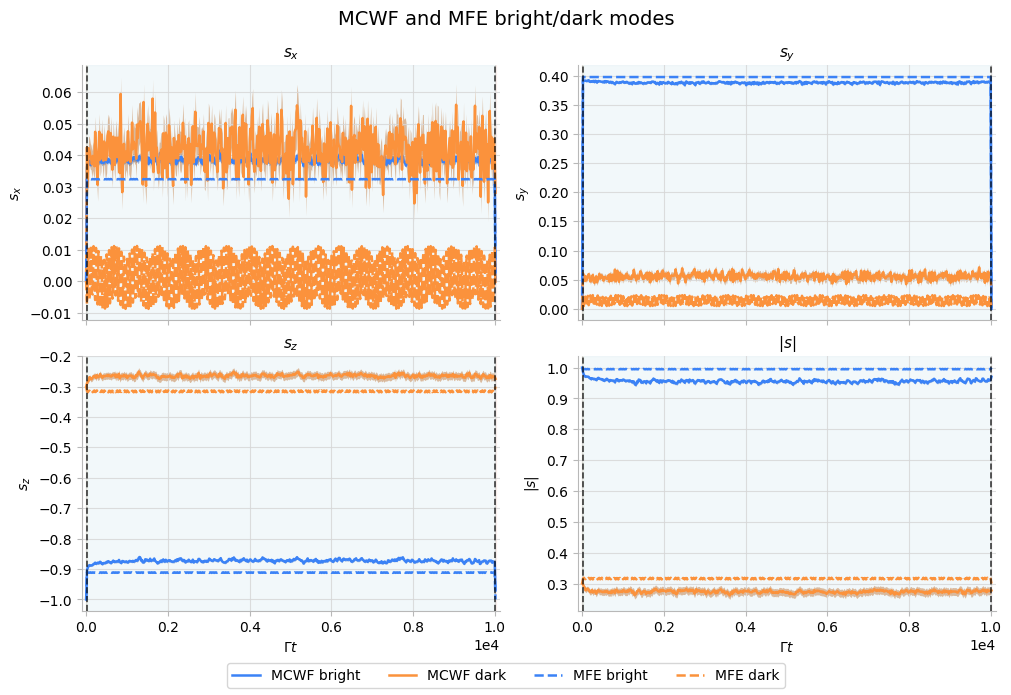

In [5]:
mode_names = ("bright", "dark")
mode_axes = None
for method_name, moments, linestyle in (
    ("MCWF", mcwf_moments, "-"),
    ("MFE", mfe_moments, "--"),
):
    modes = moments.J_modes
    vectors = tuple(getattr(modes, name) for name in mode_names)
    mode_fig, mode_axes = plot_spin_components(
        modes.t,
        tuple(vector.x for vector in vectors),
        tuple(vector.y for vector in vectors),
        tuple(vector.z for vector in vectors),
        tuple(vector.length for vector in vectors),
        x_sem=tuple(vector.x_sem for vector in vectors),
        y_sem=tuple(vector.y_sem for vector in vectors),
        z_sem=tuple(vector.z_sem for vector in vectors),
        length_sem=tuple(vector.length_sem for vector in vectors),
        labels=tuple(f"{method_name} {name}" for name in mode_names),
        phase_protocol=moments.metadata.phase_protocol,
        colour_family_index=None,
        shade_index=2,
        linestyle=linestyle,
        axes=mode_axes,
        spin_symbol="s",
        title=f"MCWF and MFE bright/dark modes",
    )

# Per-panel time labels leave the shared figure legend unobstructed.
mode_fig.supxlabel("")
for ax in mode_axes[2:]:
    ax.set_xlabel(r"$\Gamma t$")

if save_plots:
    output_dir.mkdir(parents=True, exist_ok=True)
    mode_fig.savefig(output_dir / "collective_modes.png", dpi=200, bbox_inches="tight")

## Phase-2 dark-mode traces


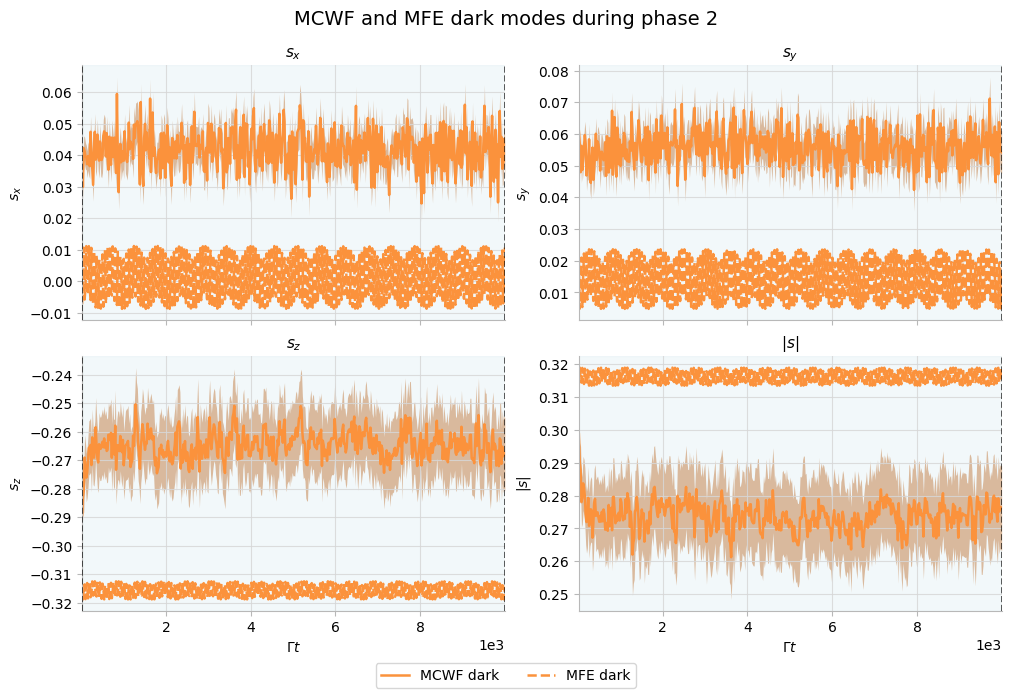

In [6]:
phase_2_traces = {}
dark_axes = None
for method_name, moments, linestyle in (
    ("MCWF", mcwf_moments, "-"),
    ("MFE", mfe_moments, "--"),
):
    dark = moments.J_modes.dark
    phase_t, phase_series = extract_family_phase_series(
        moments.J_modes.t,
        (dark.x, dark.y, dark.z, dark.length),
        moments.metadata.phase_protocol,
        family_phase_index=1,
    )
    if dark.x_sem is None:
        phase_sems = (None, None, None, None)
    else:
        _, phase_sems = extract_family_phase_series(
            moments.J_modes.t,
            (dark.x_sem, dark.y_sem, dark.z_sem, dark.length_sem),
            moments.metadata.phase_protocol,
            family_phase_index=1,
        )
    phase_2_traces[method_name] = (phase_t, phase_series[:3])
    dark_fig, dark_axes = plot_spin_components(
        phase_t,
        *phase_series,
        x_sem=phase_sems[0],
        y_sem=phase_sems[1],
        z_sem=phase_sems[2],
        length_sem=phase_sems[3],
        labels=(f"{method_name} dark",),
        phase_protocol=moments.metadata.phase_protocol,
        colour_family_index=1,
        shade_index=2,
        linestyle=linestyle,
        axes=dark_axes,
        spin_symbol="s",
        title=f"MCWF and MFE dark modes during phase 2",
    )

phase_2_t, phase_2_dark_components = phase_2_traces["MCWF"]
mfe_phase_2_t, mfe_phase_2_dark_components = phase_2_traces["MFE"]
for ax in dark_axes:
    ax.set_xlim(phase_2_t[0], phase_2_t[-1])
dark_fig.supxlabel("")
for ax in dark_axes[2:]:
    ax.set_xlabel(r"$\Gamma t$")

if save_plots:
    dark_fig.savefig(output_dir / "phase_2_dark_mode.png", dpi=200, bbox_inches="tight")

## Windowed dark-mode harmonic analysis


In [11]:
from post_analysis import (
    compute_windowed_harmonic_analysis,
    compute_j_modes_from_j_moments,
    compute_j_moments,
    compute_mean_generator_moments,
    extract_family_phase_series,
)

spectral_components = ("x", "y", "z")

# Durations use the same time units as the phase-2 traces.
window_duration = (phase_2_t[-1] - phase_2_t[0]) / 5
step_duration = window_duration / 4

dark_harmonic_analysis = compute_windowed_harmonic_analysis(
    phase_2_t,
    phase_2_dark_components,
    window_duration=window_duration,
    step_duration=step_duration,
    max_harmonic=5,
)
mfe_dark_harmonic_analysis = compute_windowed_harmonic_analysis(
    mfe_phase_2_t,
    mfe_phase_2_dark_components,
    window_duration=window_duration,
    step_duration=step_duration,
    max_harmonic=5,
)


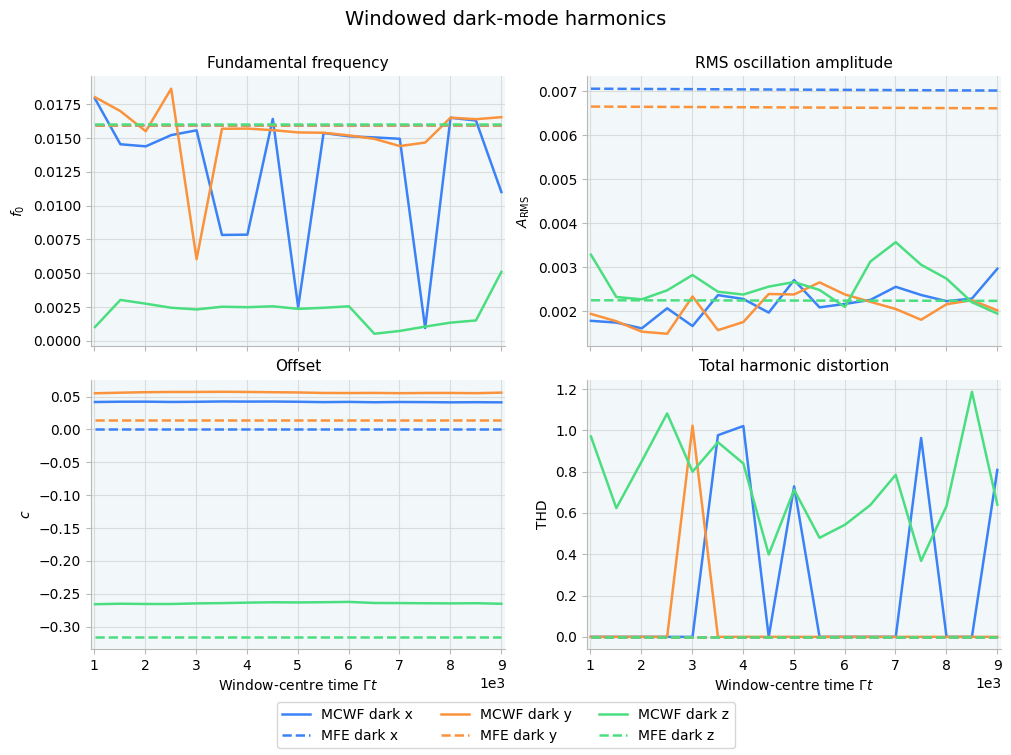

In [12]:
harmonic_fig = None
harmonic_axes = None
for method_name, analysis, linestyle in (
    ("MCWF", dark_harmonic_analysis, "-"),
    ("MFE", mfe_dark_harmonic_analysis, "--"),
):
    for component_index, component in enumerate(spectral_components):
        frequencies = analysis.fundamental_frequencies[:, component_index]
        rms_amplitudes = analysis.rms_amplitudes[:, component_index]
        offsets = analysis.offsets[:, component_index]
        distortions = analysis.total_harmonic_distortions[:, component_index]

        # The existing plotter requires finite frequency, amplitude, and offset.
        valid = (
            np.isfinite(frequencies)
            & np.isfinite(rms_amplitudes)
            & np.isfinite(offsets)
        )
        if not np.any(valid):
            print(f"No resolved windows for {method_name} dark {component}.")
            continue

        harmonic_fig, harmonic_axes = plot_harmonic_sweep(
            Gamma * analysis.window_centers[valid],
            frequencies[valid],
            distortions[valid],
            rms_amplitudes[valid],
            offsets[valid],
            labels=(f"{method_name} dark {component}",),
            parameter_label=r"Window-centre time $\Gamma t$",
            family_phase_index=1,
            colour_family_index=component_index,
            shade_index=2,
            linestyle=linestyle,
            axes=harmonic_axes,
            title="Windowed dark-mode harmonics",
        )

if harmonic_fig is None:
    print("No resolved phase-2 harmonic windows.")
elif save_plots:
    output_dir.mkdir(parents=True, exist_ok=True)
    harmonic_fig.savefig(
        output_dir / "dark_mode_harmonics.png", dpi=200, bbox_inches="tight"
    )


## Stored outputs


In [ ]:
{
    "delta/(N*Gamma)": delta_factor,
    "first moments (R, T, G, 8)": mcwf_moments.generator_moments.first_moments.shape,
    "packed second moments (R, T, K)": mcwf_moments.generator_moments.second_moments.shape,
    "mean first moments": mcwf_moments.mean_generator_moments.first_moments.shape,
    "group couplings": mcwf_moments.metadata.omega_groups,
    "MFE solve succeeded": mfe_result.success,
    "MCWF/MFE saved grids match": np.array_equal(mcwf_moments.t, mfe_moments.t),
    "phase-2 samples": phase_2_t.size,
    "harmonic window duration": window_duration,
    "harmonic step duration": step_duration,
    "MCWF fitted windows per dark component": {
        component: int(np.count_nonzero(np.isfinite(dark_harmonic_analysis.offsets[:, i])))
        for i, component in enumerate(spectral_components)
    },
    "MFE fitted windows per dark component": {
        component: int(np.count_nonzero(np.isfinite(mfe_dark_harmonic_analysis.offsets[:, i])))
        for i, component in enumerate(spectral_components)
    },
}
